### Genomför en mindre utforskande dataanalys av `customer_activity.csv`
- [x] Skiljer sig `score` mellan grupp A och grupp B?
- [x] Verkar kunder med högre `score` köpa oftare?
- [x] Skiljer sig köpfrekvensen mellan olika städer?
- [x] Hur ser fördelningen av `revenue` ut bland kunder som har genomfört ett köp?
- [x] Finns det något synligt samband mellan ålder och `score`?


- kontrollera datatyper och saknade värden,
- avgör vilka saknade värden som behöver hanteras,
- filtrera data när det behövs för analysen,
- dokumentera kort vilka beslut du fattar.

In [16]:
%load_ext autoreload 
%autoreload 2
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

import pandas as pd
df = pd.read_csv('files/customer_activity.csv')
print(df.info())
print(df.isna().sum())

# jag tänker att jag behåller all data och kör dropna() eller fyller i när/om det skulle behövas så att jag får så stort urval som möjligt
# datatyperna ser korrekta ut

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   city      795 non-null    str    
 1   gender    788 non-null    str    
 2   age       791 non-null    float64
 3   group     792 non-null    str    
 4   score     792 non-null    float64
 5   purchase  793 non-null    float64
 6   revenue   789 non-null    float64
dtypes: float64(4), str(3)
memory usage: 43.9 KB
None
city         5
gender      12
age          9
group        8
score        8
purchase     7
revenue     11
dtype: int64


# - Skiljer sig `score` mellan grupp A och grupp B?

Baserat på den deskriptiva statistiken är skillnaden mellan grupperna minimal, och grupperna kan betraktas som närmast identiska i sin benägenhet att handla.  
**Slutsats:**
Grupp B har ett marginellt högre medelvärde (+1,0 poäng) än grupp A.  
Eftersom grupperna är i princip lika stora (393 vs 391 observationer) är fördelningen mycket jämn.  
Den lilla skillnaden i medelvärde är med största sannolikhet inte praktiskt meningsfull.

In [17]:
group_a = df.loc[df['group'] == 'A', 'score'].dropna()
group_b = df.loc[df['group'] == "B", 'score'].dropna()

print(f'Totalsumma score för grupp A: {group_a.sum().round(1)}')
print(f'Totalsumma score för grupp B: {group_b.sum().round(1)}')
print(f'Medelvärde score för grupp A: {group_a.mean().round(1)}')
print(f'Medelvärde score för grupp B: {group_b.mean().round(1)}')
# grupperna skiljer sig inte åt nämnvärt för total score eller medelvärde, grupperna är nästan lika stora
print('antal grupp a:' ,len(group_a))
print('antal grupp b:' ,len(group_b))

Totalsumma score för grupp A: 24082.9
Totalsumma score för grupp B: 24346.0
Medelvärde score för grupp A: 61.3
Medelvärde score för grupp B: 62.3
antal grupp a: 393
antal grupp b: 391


## Korrelation mellan score och benägenhet att handla.
Korrelationsvärde på 0.45 visar på en måttlig positiv korrelation av ett högt score för att välja att handla.  
Båda grupperna uppvisar en relativt likartad spridning (boxarnas storlek/höjd är likvärdig), men vi kan notera enstaka extremvärden i båda ändar – exempelvis en kund som handlade trots ett mycket lågt score, samt en kund med ett score över 80 som ändå inte handlade.  
**Slutsatser:**


C:\Users\fdasfda\AppData\Local\Temp\ipykernel_10372\249293175.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='purchase', y='score', data=df, palette='colorblind')


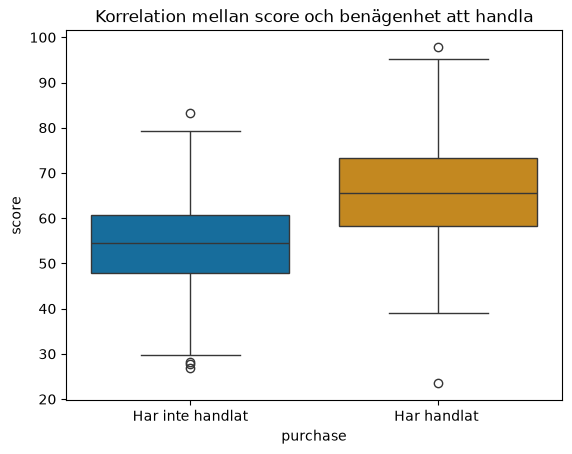

Korrelationen mellan score och purchase är: 0.4503


In [80]:
sns.boxplot(x='purchase', y='score', data=df, palette='colorblind')
plt.xticks([0, 1], ["Har inte handlat", "Har handlat "])
plt.title('Korrelation mellan score och benägenhet att handla')

plt.show()
print(f"Korrelationen mellan score och purchase är: {df['score'].corr(df['purchase']):.4f}")

## Skiljer sig köpfrekvensen mellan olika städer?
Köpfrekvensen generellt är hög i samtliga städer (ligger mellan ca 60 % och 77 %), men mönstret för vilken testgrupp (A eller B) som presterar bäst skiljer sig markant åt beroende på geografisk marknad:  
• **Uppsala** sticker ut (Högst köpfrekvens): **Uppsala** har den högsta köpfrekvensen totalt sett. Här ser vi också det starkaste resultatet för **Grupp A**.  
• I **Stockholm** är förhållandet det omvända. Där presterar **Grupp B** bättre jämfört med **Grupp A**.  
• **Göteborg** och **Malmö** är mer jämna där skillnaden är minimal.  
  
**Övergripande slutsats:**  
När vi tidigare tittade på hela datamängden verkade grupperna närmast identiska i sitt beteende.  
Denna stadsanalys avslöjar dock en viktig nyans: testgruppernas effekt är geografiskt polariserad.
**Grupp B** fungerar bäst i **Stockholm**, medan **Grupp A** är klart starkast i **Uppsala**.  
Det indikerar att det kan finnas bakomliggande lokala faktorer (eller skillnader i vilka kundgrupper som finns i de olika städerna) som påverkar hur grupperna reagerar på "score".

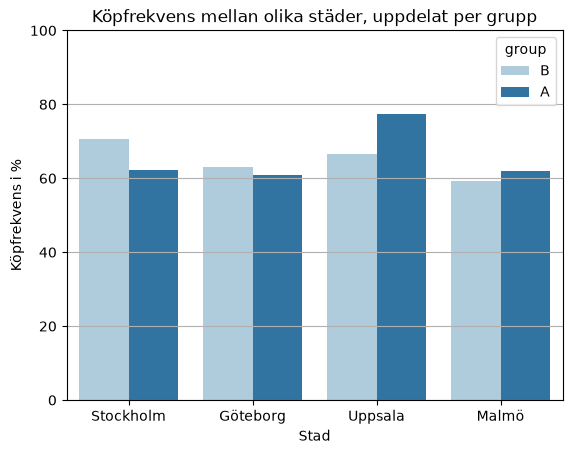

           Köpfrekvens Grupp A  Köpfrekvens Grupp B  Skillnad (A - B)
city                                                                 
Göteborg                  60.8                 63.0              -2.2
Malmö                     62.0                 59.4               2.6
Stockholm                 62.2                 70.6              -8.4
Uppsala                   77.3                 66.7              10.6


In [114]:
sns.barplot(x='city', y='purchase', data=df, palette='Paired',hue='group', estimator=lambda x: np.mean(x) * 100, errorbar=None)
plt.title('Köpfrekvens mellan olika städer, uppdelat per grupp')
plt.ylabel('Köpfrekvens i %')
plt.xlabel('Stad')
plt.grid(axis='y')
plt.ylim(0, 100)
plt.show()

purch_freq = (df.groupby(['city', 'group'])['purchase'].mean() * 100).unstack().round(1)
purch_freq.columns = ['Köpfrekvens Grupp A', 'Köpfrekvens Grupp B']
purch_freq['Skillnad (A - B)'] = purch_freq['Köpfrekvens Grupp A'] - purch_freq['Köpfrekvens Grupp B']
print(purch_freq)


## Hur ser fördelningen av revenue ut bland kunder som har genomfört ett köp?
Tyngdpunkten ligger runt 20 kr där den absoluta toppen ligger, där enskilda staplar når upp till över 60 köp.  
 De allra flesta köpen sker i intervallet mellan 10 och 40 kr.  
Köp över 50 kr är sällsynta, och transaktioner över 80 kr förekommer bara i enstaka fall.

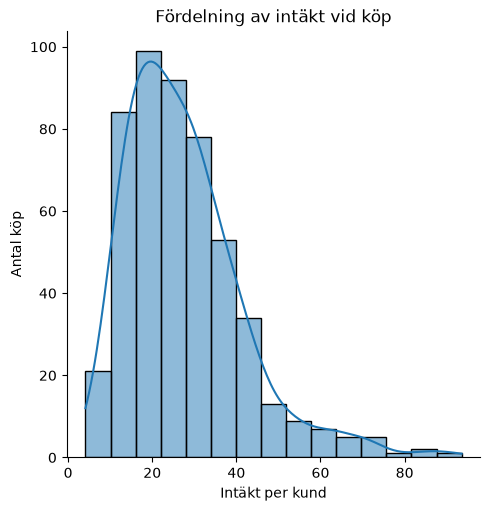

In [91]:
# filters directly on data, amazing!
sns.displot(data=df[df['purchase']==1], x='revenue', kde=True, bins = 15)
plt.title('Fördelning av intäkt vid köp')
plt.ylabel('Antal köp')
plt.xlabel('Intäkt per kund')
plt.savefig("files/week5_displot.png", dpi=150)
plt.show()


## Finns det något synligt samband mellan ålder och score?
Det verkar saknas ett meningsfullt samband helt och hållet. Linjen är i princip helt plan, vilket betyder att en kunds ålder inte har någon påverkan på vilken poäng (score) de får.
Korrelation på 0.07 pekar på att den är obefintlig.

Korrelationen mellan ålder och score är: 0.0770


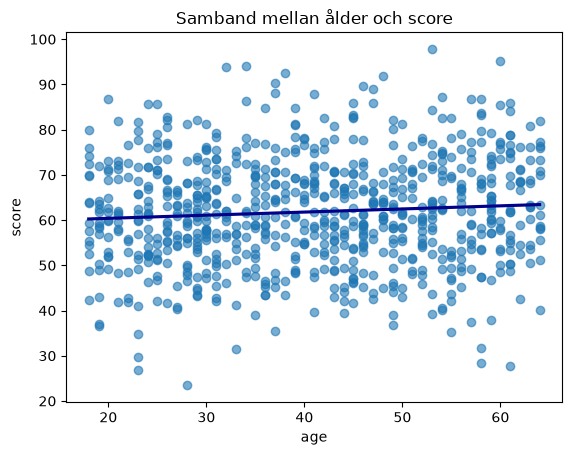

In [89]:
sns.regplot(x='age', y='score' , data= df, scatter_kws={'alpha': 0.6}, line_kws={'color': 'darkblue'},ci=None)
plt.title('Samband mellan ålder och score')
print(f"Korrelationen mellan ålder och score är: {df['age'].corr(df['score']):.4f}")

Använd lämpliga sammanfattningar, exempelvis:

- antal och andelar,
- medelvärde och median,
- gruppering med `groupby()`,
- frekvenstabeller.

- [x] Skapa minst tre visualiseringar som hjälper dig att besvara frågorna.

- [x] Välj figurtyp utifrån vilken typ av fråga och vilka variabler du undersöker. Varje figur ska ha:

- en tydlig titel,
- relevanta axelrubriker,
- läsbar skala och layout,
- en legend när den behövs.

- [x] Spara minst en figur som en bildfil.

- [x] Skriv 3–5 korta observationer från analysen. Skilj mellan:

- vad som faktiskt syns i data,
- möjliga förklaringar som skulle behöva undersökas vidare.

Undvik att beskriva samband som orsakssamband om analysen inte ger stöd för det.